In [22]:
import sys
from pathlib import Path

project_root = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from backend.data_workflow import clean_youtube_data, load_sample_data

print("Shared data workflow loaded from backend/data_workflow.py")


Shared data workflow loaded from backend/data_workflow.py


In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


Load dataset

In [24]:
sample_path = project_root / "data" / "sample_youtube_data.csv"
df = pd.read_csv(sample_path)

df.head()


,Channel,Month,Subscribers,Views,Likes
0,Tech World,Jan,100000,500000,25000
1,Tech World,Feb,115000,650000,32000
2,Tech World,Mar,128000,800000,40000
3,Tech World,Apr,145000,950000,47000
4,Tech World,May,170000,1200000,60000


Data inspection and exploratory data analysis

In [25]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
df.describe()

Dataset Shape: (15, 5)

Column Names:
['Channel', 'Month', 'Subscribers', 'Views', 'Likes']

Data Types:
Channel          str
Month            str
Subscribers    int64
Views          int64
Likes          int64
dtype: object

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Channel      15 non-null     str  
 1   Month        15 non-null     str  
 2   Subscribers  15 non-null     int64
 3   Views        15 non-null     int64
 4   Likes        15 non-null     int64
dtypes: int64(3), str(2)
memory usage: 732.0 bytes

Statistical Summary:


,Subscribers,Views,Likes
count,15.000000,1.500000e+01,15.000000
mean,106266.666667,6.133333e+05,29600.000000
std,30952.652013,2.954093e+05,14029.560628
min,58000.000000,2.000000e+05,10000.000000
25%,87500.000000,4.000000e+05,19500.000000
50%,100000.000000,5.200000e+05,25000.000000
75%,124000.000000,8.250000e+05,39000.000000
max,170000.000000,1.200000e+06,60000.000000


Missing values

In [26]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Channel        0
Month          0
Subscribers    0
Views          0
Likes          0
dtype: int64


Duplicates

In [27]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


Data cleaning

In [28]:
clean_df, cleaning_summary = clean_youtube_data(df)

print("Original Rows:", cleaning_summary["original_count"])
print("Cleaned Rows:", cleaning_summary["final_count"])
print("Missing cells detected:", cleaning_summary["missing_count"])
print("Duplicate rows removed:", cleaning_summary["duplicate_count"])
print("Invalid numeric rows:", cleaning_summary["invalid_rows"])

clean_df.head()


Original Rows: 15
Cleaned Rows: 15
Missing cells detected: 0
Duplicate rows removed: 0
Invalid numeric rows: 0


,Channel,Month,Subscribers,Views,Likes
0,Tech World,Jan,100000,500000,25000
1,Tech World,Feb,115000,650000,32000
2,Tech World,Mar,128000,800000,40000
3,Tech World,Apr,145000,950000,47000
4,Tech World,May,170000,1200000,60000


Histogram

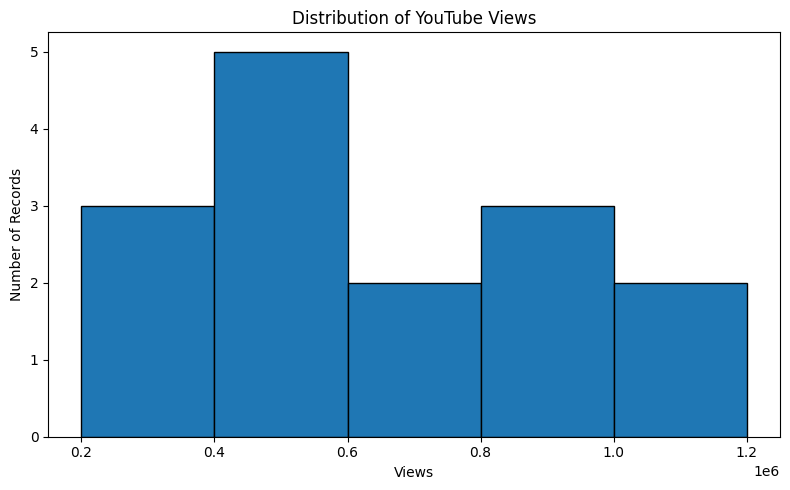

In [29]:
plt.figure(figsize=(8, 5))

plt.hist(clean_df["Views"], bins=5, edgecolor="black")

plt.title("Distribution of YouTube Views")
plt.xlabel("Views")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

Scatter plot

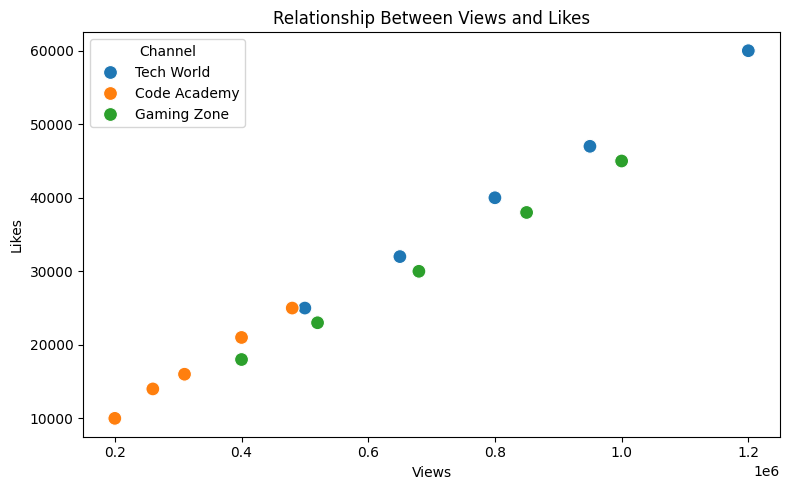

In [30]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=clean_df,
    x="Views",
    y="Likes",
    hue="Channel",
    s=100
)

plt.title("Relationship Between Views and Likes")
plt.xlabel("Views")
plt.ylabel("Likes")

plt.tight_layout()
plt.show()

Line plot

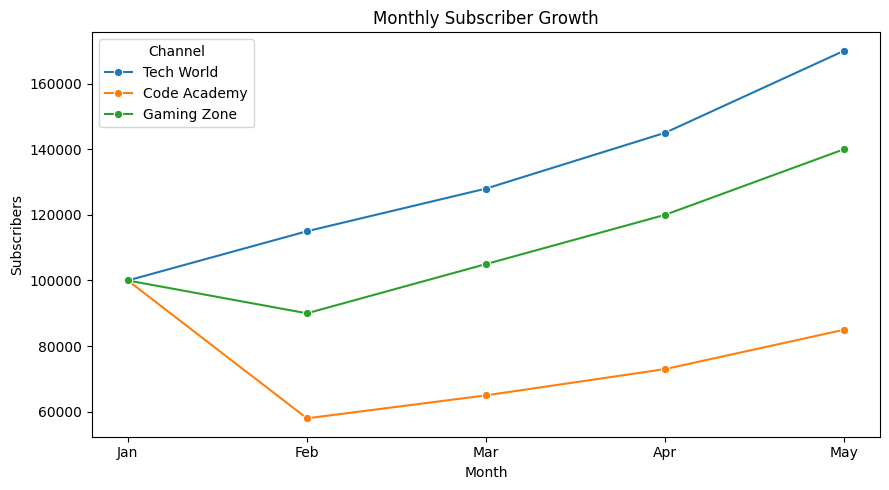

In [31]:
plt.figure(figsize=(9, 5))

sns.lineplot(
    data=clean_df,
    x="Month",
    y="Subscribers",
    hue="Channel",
    marker="o"
)

plt.title("Monthly Subscriber Growth")
plt.xlabel("Month")
plt.ylabel("Subscribers")

plt.tight_layout()
plt.show()

Cleaned dataset

In [32]:
output_path = project_root / "data" / "cleaned_youtube_data.csv"
clean_df.to_csv(output_path, index=False)

print("Cleaned dataset exported successfully to:", output_path)


Cleaned dataset exported successfully to: D:\College\DWP-PROJ\youtube-data-analytics\data\cleaned_youtube_data.csv
